### Problem Statement: Software Defect Prediction Using Machine Learning

The objective of this project is to predict software defects using the CM1 dataset and machine learning techniques. The process involves data cleaning, exploratory data analysis, outlier treatment, correlation analysis, feature selection, and feature scaling.

An SVM classifier is developed to classify software modules as defective or non-defective. Model performance is evaluated using accuracy, precision, recall, F1-score, and a confusion matrix. Class weighting is also explored to address class imbalance and improve defect detection.

**Goal:** Identify potentially defective software modules to help prioritize testing efforts and improve software quality.


In [2]:
# ============================================================
#          1. IMPORT REQUIRED LIBRARIES
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from keras.models import Model, Sequential
from keras.layers import Flatten, Dense, Activation
from keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from scipy.io import arff

# ============================================================
#          2. LOAD THE DATASET
# ============================================================

# Load the CM1 software defect prediction dataset
data = pd.read_csv(
    r"C:\Users\rroha\OneDrive\Desktop\Bits_Pilani_LF_Raj\Webinar3_Bits\cm1.csv"
)

# Store the original feature names
originalfeatures = data.columns

# Display the number of columns
print("Original features length:", len(originalfeatures))

# Display all column names
print("Original features:", originalfeatures)

data.head()

Original features length: 22
Original features: Index(['loc', 'v(g)', 'ev(g)', 'iv(g)', 'n', 'v', 'l', 'd', 'i', 'e', 'b', 't',
       'lOCode', 'lOComment', 'lOBlank', 'locCodeAndComment', 'uniq_Op',
       'uniq_Opnd', 'total_Op', 'total_Opnd', 'branchCount', 'defects'],
      dtype='object')


,loc,v(g),ev(g),iv(g),n,v,l,d,i,e,...,lOCode,lOComment,lOBlank,locCodeAndComment,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount,defects
0,1.1,1.4,1.4,1.4,1.3,1.30,1.30,1.30,1.30,1.30,...,2,2,2,2,1.2,1.2,1.2,1.2,1.4,False
1,1.0,1.0,1.0,1.0,1.0,1.00,1.00,1.00,1.00,1.00,...,1,1,1,1,1.0,1.0,1.0,1.0,1.0,True
2,24.0,5.0,1.0,3.0,63.0,309.13,0.11,9.50,32.54,2936.77,...,1,0,6,0,15.0,15.0,44.0,19.0,9.0,False
3,20.0,4.0,4.0,2.0,47.0,215.49,0.06,16.00,13.47,3447.89,...,0,0,3,0,16.0,8.0,31.0,16.0,7.0,False
4,24.0,6.0,6.0,2.0,72.0,346.13,0.06,17.33,19.97,5999.58,...,0,0,3,0,16.0,12.0,46.0,26.0,11.0,False


In [3]:
# ============================================================
#          3. CONVERT BOOLEAN TARGET VALUES TO INTEGERS
# ============================================================

# Define a function to convert Boolean values into integers
def map_bool_to_int(value):
    if value is True:
        return 1
    elif value is False:
        return 0
    else:
        return None

# Convert Boolean values in the 'defects' column
data['defects'] = data['defects'].apply(map_bool_to_int)

# Display the updated target column
print(data['defects'].value_counts(dropna=False))

defects
0    449
1     49
Name: count, dtype: int64


In [4]:
X=data.drop(labels=['defects'], axis=1)
y=data['defects']

In [5]:
# ============================================================
#          4. DATA CLEANING AND MISSING VALUE IMPUTATION
# ============================================================

# Create an empty list to store the cleaning results
cleaning_results = []

# Check each column for non-numeric values and missing values
for column in data.columns:

    # Convert the column to numeric, coercing invalid values to NaN
    numeric_column = pd.to_numeric(data[column], errors='coerce')

    # Identify values that could not be converted or were already missing
    non_numeric_indices = numeric_column.isna()

    # Count missing or non-numeric values
    missing_count = non_numeric_indices.sum()

    # Calculate the mean of the numeric values
    mean_col = numeric_column.mean()

    # Replace missing values with the column mean
    if missing_count > 0:
        data[column] = numeric_column.fillna(mean_col)
        status = "Missing values replaced with mean"
    else:
        data[column] = numeric_column
        status = "No missing values"

    # Store the cleaning details
    cleaning_results.append({
        'Column Name': column,
        'Missing/Non-Numeric Values': missing_count,
        'Mean Used for Imputation': mean_col if missing_count > 0 else None,
        'Cleaning Status': status
    })

# Convert the results into a DataFrame
cleaning_summary = pd.DataFrame(cleaning_results)

# Display the cleaning summary
cleaning_summary

,Column Name,Missing/Non-Numeric Values,Mean Used for Imputation,Cleaning Status
0,loc,0,None,No missing values
1,v(g),0,None,No missing values
2,ev(g),0,None,No missing values
3,iv(g),0,None,No missing values
4,n,0,None,No missing values
5,v,0,None,No missing values
6,l,0,None,No missing values
7,d,0,None,No missing values
8,i,0,None,No missing values
9,e,0,None,No missing values


In [8]:
# ============================================================
#          5. DESCRIPTIVE STATISTICS
# ============================================================

# Generate summary statistics for all numerical columns

data.describe()

,loc,v(g),ev(g),iv(g),n,v,l,d,i,e,...,lOCode,lOComment,lOBlank,locCodeAndComment,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount,defects
count,498.000000,498.000000,498.000000,498.000000,498.000000,498.000000,498.000000,498.000000,498.000000,4.980000e+02,...,498.000000,498.000000,498.000000,498.000000,498.000000,498.000000,498.000000,498.000000,498.000000,498.000000
mean,29.644779,5.382329,2.490763,3.528916,143.956426,900.175823,0.146325,15.829378,38.455361,3.488493e+04,...,3.787149,12.283133,11.534137,0.006024,15.199197,25.452209,88.389960,55.570683,9.348193,0.098394
std,42.753572,8.347359,3.658847,5.464398,221.049888,1690.814334,0.159337,15.330960,36.996297,1.341647e+05,...,8.508658,25.828605,19.981476,0.100120,9.617815,33.925816,134.917513,86.969527,15.072219,0.298146
min,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000
25%,8.000000,1.000000,1.000000,1.000000,25.000000,102.190000,0.050000,5.630000,16.210000,6.061700e+02,...,0.000000,0.000000,1.000000,0.000000,9.000000,7.000000,15.000000,10.000000,1.000000,0.000000
50%,17.000000,3.000000,1.000000,2.000000,67.500000,329.820000,0.090000,11.640000,27.400000,3.677620e+03,...,1.000000,4.000000,5.000000,0.000000,14.000000,15.000000,42.000000,26.000000,5.000000,0.000000
75%,31.000000,6.000000,1.000000,4.000000,151.750000,861.460000,0.177500,21.142500,46.900000,1.663334e+04,...,4.000000,14.000000,13.000000,0.000000,20.000000,30.000000,94.750000,59.750000,11.000000,0.000000
max,423.000000,96.000000,30.000000,63.000000,2075.000000,17124.280000,1.300000,125.770000,293.680000,2.153691e+06,...,80.000000,339.000000,164.000000,2.000000,72.000000,314.000000,1261.000000,814.000000,162.000000,1.000000


In [ ]:
# 7.1 SAVE ORIGINAL DATA BEFORE OUTLIER TREATMENT

X = data.drop(columns=['defects']).copy()

# Keep an untouched copy for comparison
X_before = X.copy()

# Select the first six numerical features for visualization
numerical_columns = X.select_dtypes(include=np.number).columns
plot_columns = numerical_columns[:6]

print("Original data saved successfully.")
print("Features selected for plotting:", list(plot_columns))

Original data saved successfully.
Features selected for plotting: ['loc', 'v(g)', 'ev(g)', 'iv(g)', 'n', 'v']


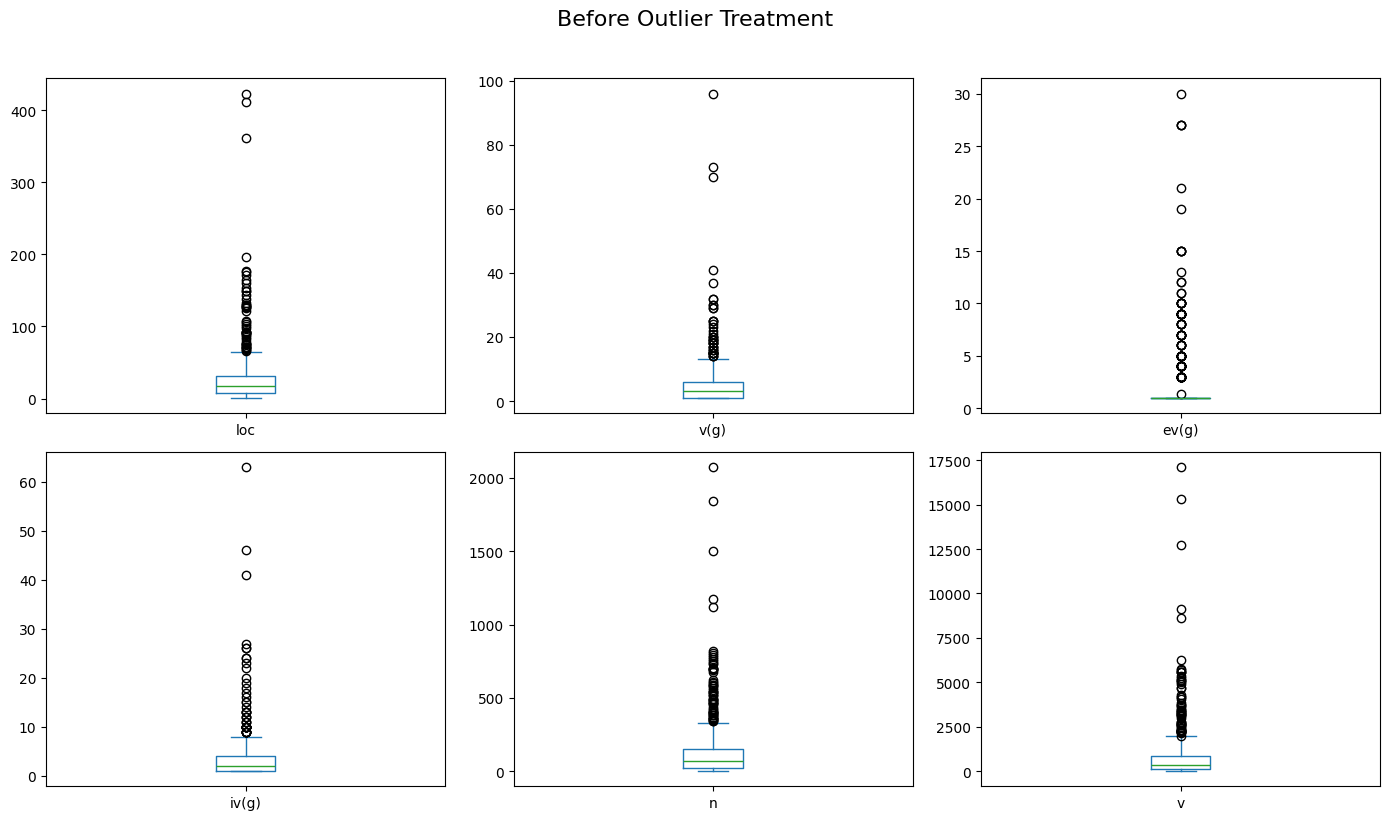

In [22]:
# 7.2 OUTLIERS BEFORE TREATMENT

X_before[plot_columns].plot(
    kind='box',
    subplots=True,
    layout=(2, 3),
    figsize=(14, 8),
    sharex=False,
    sharey=False
)

plt.suptitle("Before Outlier Treatment", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

In [23]:
# 7.3 TREAT OUTLIERS USING IQR CAPPING

X_after = X_before.copy()

for column in numerical_columns:
    Q1 = X_before[column].quantile(0.25)
    Q3 = X_before[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    X_after[column] = X_before[column].clip(
        lower=lower_limit,
        upper=upper_limit
    )

print("IQR-based outlier capping completed.")

IQR-based outlier capping completed.


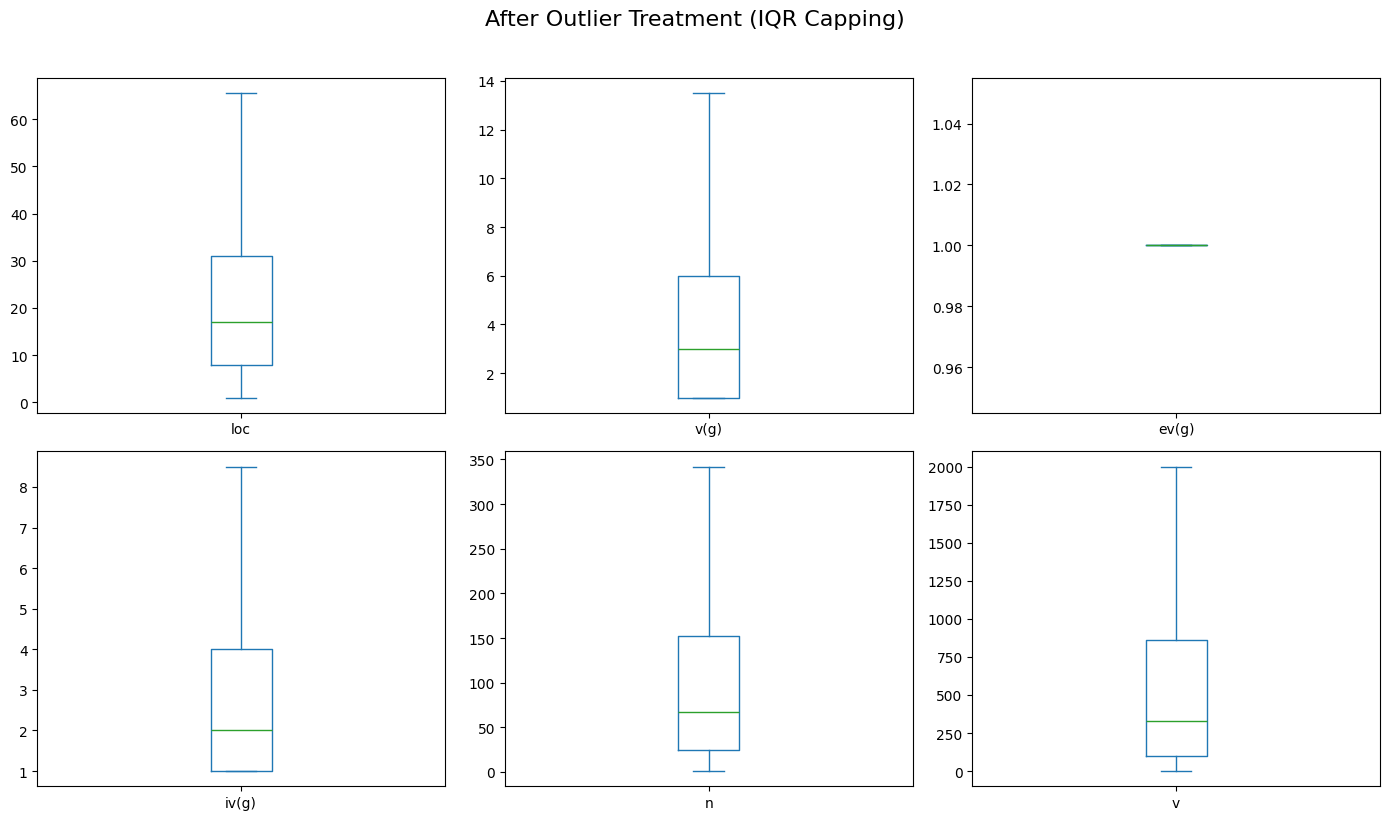

In [24]:
# 7.4 OUTLIERS AFTER TREATMENT

X_after[plot_columns].plot(
    kind='box',
    subplots=True,
    layout=(2, 3),
    figsize=(14, 8),
    sharex=False,
    sharey=False
)

plt.suptitle("After Outlier Treatment (IQR Capping)", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

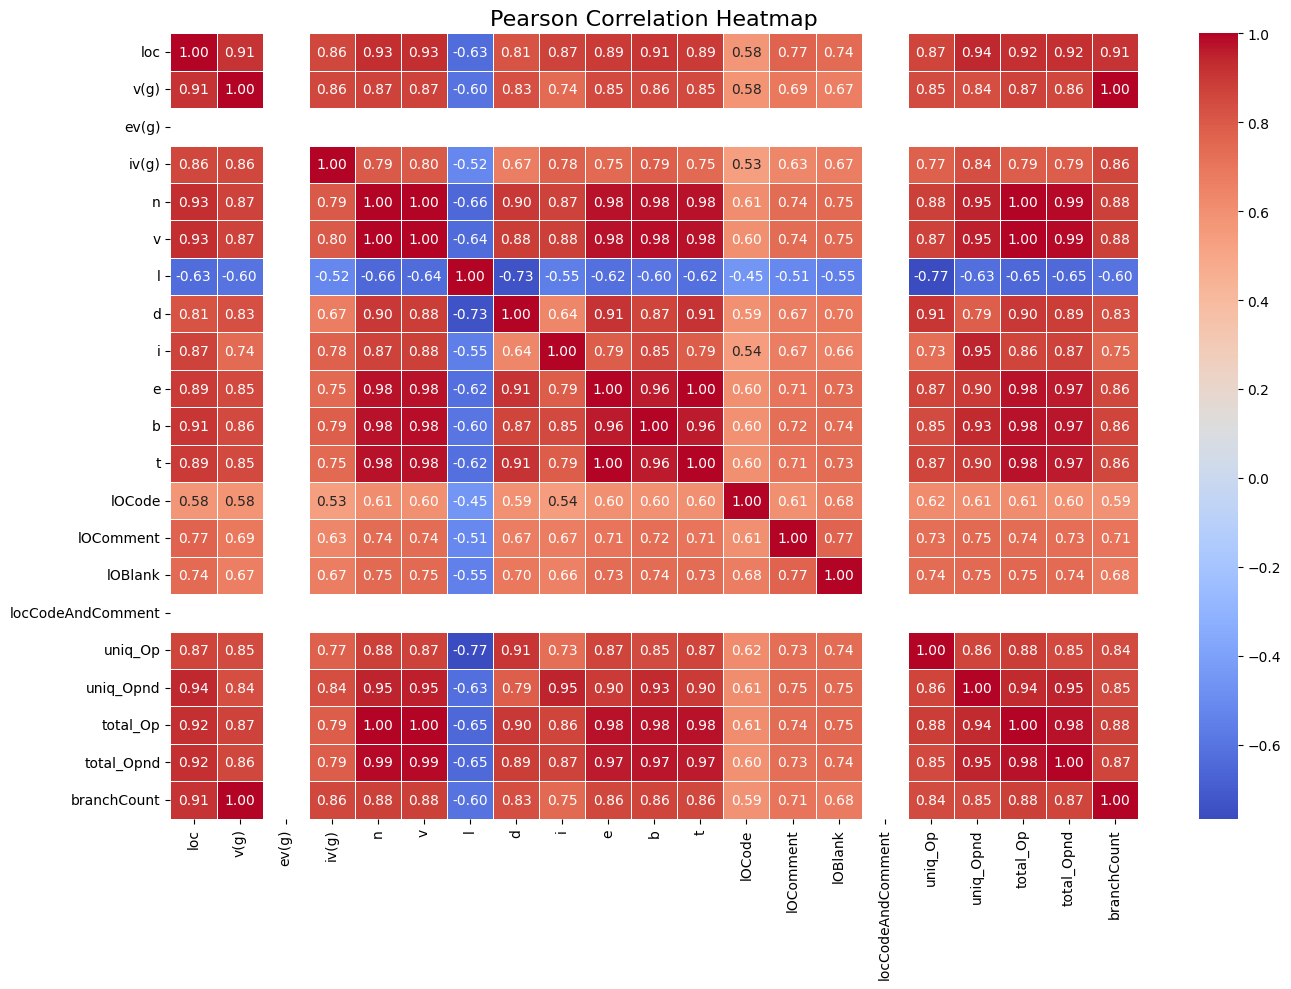

In [ ]:
# PEARSON CORRELATION HEATMAP

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate Pearson correlation between numerical features
cor = X_after.corr()

# Visualize the correlation matrix
plt.figure(figsize=(14, 10))

sns.heatmap(
    cor,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Pearson Correlation Heatmap", fontsize=16)
plt.tight_layout()
plt.show()

The Pearson correlation heatmap reveals strong positive correlations among several software metrics, particularly n, v, e, b, t, total_Op, and total_Opnd. The feature l exhibits negative correlations with multiple other metrics. These patterns suggest potential multicollinearity and redundancy among some predictors. Before model training, the highly correlated features should be investigated, and any feature selection should be validated against model performance.

In [ ]:
# IDENTIFY HIGHLY CORRELATED FEATURES

def correlation(dataset, threshold):

    # Calculate the correlation matrix
    corr_matrix = dataset.corr()

    # Store names of highly correlated features
    col_corr = set()

    # Compare each pair of features
    for i in range(len(corr_matrix.columns)):
        for j in range(i):

            # Check absolute correlation against threshold
            if abs(corr_matrix.iloc[i, j]) > threshold:
                colname = corr_matrix.columns[i]
                col_corr.add(colname)

    return col_corr


# Set correlation threshold to 0.97
corr_features = correlation(X_after, 0.97)

# Display the results
print("Number of highly correlated features:", len(corr_features))
print("Highly correlated features:", corr_features)

Number of highly correlated features: 7
Highly correlated features: {'b', 'branchCount', 'total_Op', 'e', 'total_Opnd', 'v', 't'}


In [28]:
# REMOVE HIGHLY CORRELATED FEATURES

X = X.drop(list(corr_features), axis=1)

# Display remaining features
print("Shape after feature removal:", X.shape)
print("\nRemaining features:")
print(X.columns.tolist())

Shape after feature removal: (498, 14)

Remaining features:
['loc', 'v(g)', 'ev(g)', 'iv(g)', 'n', 'l', 'd', 'i', 'lOCode', 'lOComment', 'lOBlank', 'locCodeAndComment', 'uniq_Op', 'uniq_Opnd']


Highly correlated features were removed because they contain similar information. Keeping both may be unnecessary and can make it difficult to understand the model's results. Removing redundant features simplifies the dataset and can help Logistic Regression perform more reliably. We will compare the model's performance before and after removing these features to check whether the change improves defect prediction.


In [30]:
# FEATURE SCALING USING MINMAXSCALER

from sklearn.preprocessing import MinMaxScaler
from pandas import DataFrame

# Initialize the scaler
trans = MinMaxScaler()

# Scale the features
X_scaled = trans.fit_transform(X)

# Convert the scaled array back to a DataFrame
X = DataFrame(X_scaled, columns=X.columns if isinstance(X, DataFrame) else None)
X

,loc,v(g),ev(g),iv(g),n,l,d,i,lOCode,lOComment,lOBlank,locCodeAndComment,uniq_Op,uniq_Opnd
0,0.000237,0.004211,0.013793,0.006452,0.000145,1.000000,0.010336,0.004427,0.0250,0.005900,0.012195,1.0,0.002817,0.003822
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.769231,0.007951,0.003405,0.0125,0.002950,0.006098,0.5,0.000000,0.003185
2,0.054502,0.042105,0.000000,0.032258,0.029894,0.084615,0.075535,0.110801,0.0125,0.000000,0.036585,0.0,0.197183,0.047771
3,0.045024,0.031579,0.103448,0.016129,0.022179,0.046154,0.127216,0.045866,0.0000,0.000000,0.018293,0.0,0.211268,0.025478
4,0.054502,0.052632,0.172414,0.016129,0.034233,0.046154,0.137791,0.067999,0.0000,0.000000,0.018293,0.0,0.211268,0.038217
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
493,0.109005,0.021053,0.000000,0.032258,0.122951,0.030769,0.222629,0.190173,0.0250,0.038348,0.012195,0.0,0.309859,0.146497
494,0.054502,0.031579,0.068966,0.032258,0.051109,0.038462,0.152103,0.104604,0.0125,0.020649,0.024390,0.0,0.295775,0.073248
495,0.191943,0.105263,0.068966,0.145161,0.228544,0.015385,0.355490,0.240364,0.1125,0.174041,0.213415,0.0,0.436620,0.216561
496,0.021327,0.010526,0.000000,0.000000,0.014947,0.115385,0.051682,0.078793,0.0125,0.035398,0.024390,0.0,0.169014,0.041401


Training samples: 348
Testing samples: 150

SVM model training completed successfully.

SVM Model Accuracy: 90.0 %

Confusion Matrix:
[[135   0]
 [ 15   0]]


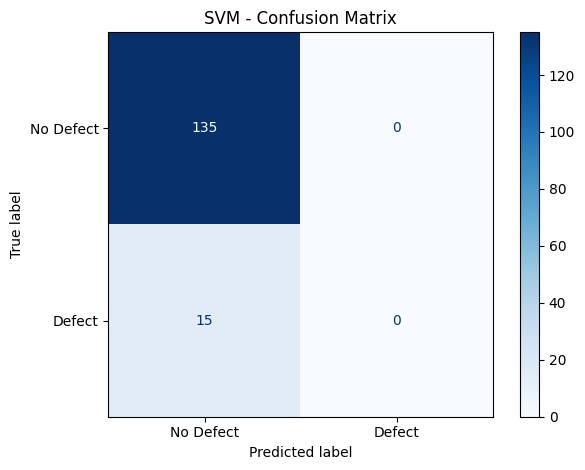


Classification Report:
              precision    recall  f1-score   support

   No Defect       0.90      1.00      0.95       135
      Defect       0.00      0.00      0.00        15

    accuracy                           0.90       150
   macro avg       0.45      0.50      0.47       150
weighted avg       0.81      0.90      0.85       150



In [31]:
# SUPPORT VECTOR MACHINE (SVM) CLASSIFICATION

# Step 1: Import required libraries

from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Step 2: Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=100,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# Step 3: Initialize the SVM classifier
svm_classifier = SVC(
    kernel='linear',
    C=1.0,
    random_state=100
)

# Step 4: Train the model
svm_classifier.fit(X_train, y_train)

print("\nSVM model training completed successfully.")

# Step 5: Predict software defects on the test set
y_pred_svm = svm_classifier.predict(X_test)

# Step 6: Evaluate model accuracy
accuracy_svm = accuracy_score(y_test, y_pred_svm)

print("\nSVM Model Accuracy:", round(accuracy_svm * 100, 2), "%")

# Step 7: Generate the confusion matrix
conf_matrix_svm = confusion_matrix(y_test, y_pred_svm)

print("\nConfusion Matrix:")
print(conf_matrix_svm)

# Step 8: Display the confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=conf_matrix_svm,
    display_labels=['No Defect', 'Defect']
).plot(cmap='Blues', values_format='d')

plt.title("SVM - Confusion Matrix")
plt.tight_layout()
plt.show()

# Step 9: Generate the classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_svm,
        target_names=['No Defect', 'Defect'],
        zero_division=0
    )
)

The SVM classifier achieved 90% accuracy on the test dataset. However, the confusion matrix showed that it classified all 150 modules as non-defective, missing all 15 defective modules. This demonstrates that accuracy alone is insufficient when evaluating an imbalanced dataset. Further model tuning and class-weight adjustment are needed to improve defect detection.

## Support Vector Machine (SVM) – Software Defect Prediction

### 1. What is SVM?

Support Vector Machine (SVM) is a supervised machine learning algorithm used for classification. In our CM1 project, it predicts whether a software module contains a defect.

SVM identifies an optimal decision boundary to separate the two classes:

- **No Defect (0):** The software module is classified as non-defective.
- **Defect (1):** The software module is classified as defective.

### 2. Understanding the Results

The SVM model achieved **90% accuracy** on the test dataset. However, the confusion matrix reveals an important limitation.

The test dataset contains 150 samples:

- **135 non-defective modules**
- **15 defective modules**

The model correctly classified all 135 non-defective modules but failed to identify any of the 15 defective modules. In other words, it predicted every module as **No Defect**.

### 3. Why Is Accuracy Misleading?

Accuracy measures the proportion of correctly classified samples.

$$
\text{Accuracy} = \frac{\text{Correct Predictions}}{\text{Total Predictions}} \times 100
$$

For our model:

$$
\text{Accuracy} = \frac{135}{150} \times 100 = 90\%
$$

Since 90% of the test samples are non-defective, a model that always predicts No Defect can achieve 90% accuracy without identifying a single defective module.

### 4. Understanding the Evaluation Metrics

- **Precision (Defect): 0%** – The model did not predict any modules as defective.
- **Recall (Defect): 0%** – The model failed to identify any of the 15 defective modules.
- **F1-score (Defect): 0%** – The model failed to identify defective modules effectively.

### 5. Conclusion

Although the SVM model achieved 90% accuracy, it failed to detect any defective software modules. Therefore, accuracy alone is not sufficient to evaluate the model's performance.

Since the primary objective of software defect prediction is to identify defective modules, the model needs further improvement. Techniques such as class weighting and model tuning can be explored to improve defect detection.

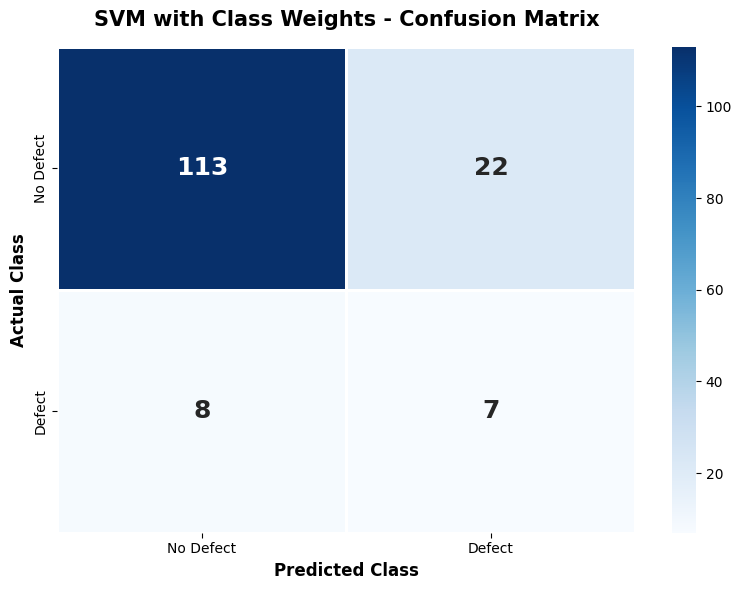


Classification Report:
              precision    recall  f1-score   support

   No Defect       0.93      0.84      0.88       135
      Defect       0.24      0.47      0.32        15

    accuracy                           0.80       150
   macro avg       0.59      0.65      0.60       150
weighted avg       0.86      0.80      0.83       150



In [ ]:
# SVM WITH CLASS WEIGHTS - CONFUSION MATRIX 

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred_balanced)

# Create a professional visualization
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=2,
    linecolor='white',
    xticklabels=['No Defect', 'Defect'],
    yticklabels=['No Defect', 'Defect'],
    annot_kws={'size': 18, 'weight': 'bold'},
    cbar=True
)

plt.title(
    'SVM with Class Weights - Confusion Matrix',
    fontsize=15,
    fontweight='bold',
    pad=15
)

plt.xlabel('Predicted Class', fontsize=12, fontweight='bold')
plt.ylabel('Actual Class', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_balanced,
    target_names=['No Defect', 'Defect'],
    zero_division=0
))

Original SVM: The model achieved 90% accuracy but classified every test sample as non-defective. It failed to identify any of the 15 defective modules.

SVM with class weights: Accuracy decreased to 80%, but the model correctly identified 7 of the 15 defective modules. Defect recall improved from 0% to approximately 47%.

Business implication: The class-weighted model is more useful for defect screening because it identifies some defective modules. However, its low defect precision means that many flagged modules are actually non-defective, and additional tuning is required.